# Практическая работа №1. iPhone или Android: метод k ближайших соседей

**Цель:** по ответам анкеты предсказать используемый тип телефона: Android (0) или iPhone (1). Целевая переменная отражает текущий телефон, а не обязательно предпочтение человека.

Работа адаптирована из Practice_1.ipynb: сохранены евклидово расстояние, собственная реализация взвешенного k-NN, анализ k и демонстрация соседей. Вместо химических характеристик используются смешанные числовые и категориальные ответы. 

План: проверка данных → подготовка признаков → независимый тест 20% → подбор k по 4 блокам внутри обучения → оценка и визуализация. Готовый классификатор sklearn не используется.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize': (9, 5), 'font.family': 'DejaVu Sans'})
SEED = 42
CLASS_NAMES = {0: 'Android', 1: 'iPhone'}
DATA_PATH = Path('data/phone_preferences.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('outputs/data/phone_preferences.csv')
raw = pd.read_csv(DATA_PATH, dtype=str).fillna('')
assert raw.shape[1] == 23, 'Ожидались отметка времени и 22 вопроса'
raw.columns = ['timestamp'] + [f'q{i}' for i in range(1, 23)]
raw = raw.apply(lambda s: s.str.strip())
print('Размер исходных данных:', raw.shape)
display(raw.head())
display(pd.DataFrame({'вопрос': ['Время'] + list(range(1, 23)), 'заголовок': pd.read_csv(DATA_PATH, nrows=0).columns}))
print('Пустых ответов:', int((raw == '').sum().sum()))
print('Повторов анкет без времени:', int(raw.drop(columns='timestamp').duplicated().sum()))

Размер исходных данных: (41, 23)


,timestamp,q1,q2,q3,q4,q5,q6,q7,q8,q9,...,q13,q14,q15,q16,q17,q18,q19,q20,q21,q22
0,2026/09/14 8:05:47 PM GMT+3,Стабильность,Раз в неделю,Нет,Экосистема;Надежность,Технологичность,VPN,21,80000,5,...,3,Не важна,IT,М,Нет,1,Экономить и откладывать,От одного бренда,1,Андроид
1,2026/09/14 8:05:56 PM GMT+3,Стабильность,Каждый день,Да,Статус;Камера,Статус,VPN,21,90000,6,...,3,Важна,Продажи,М,Да,5,Экономить и откладывать,От одного бренда,7,Айфон
2,2026/09/14 8:06:41 PM GMT+3,Новшество,Раз в неделю,Нет,Экосистема;Надежность;Мультивыбор,Статус,VPN,22,60,5,...,3,Важна,Менеджер,М,Нет,2,Порадовать себя,От одного бренда,4,Айфон
3,2026/09/14 8:07:06 PM GMT+3,Стабильность,Раз в месяц,Нет,Надежность,Технологичность,VPN,22,50000,1,...,7,Не важна,Студент,М,Нет,1,Экономить и откладывать,От разных брендов,10,Айфон
4,2026/09/14 8:07:09 PM GMT+3,Стабильность,Раз в неделю,Нет,Камера;Экосистема;Надежность,Технологичность,VPN,22,30000,3,...,2.5,Важна,Тех под,М,Нет,2,Экономить и откладывать,От разных брендов,1,Андроид


,вопрос,заголовок
0,Время,Отметка времени
1,1,1. Стабильность или новшество?
2,2,2. Часто ли вы фотографируете?
3,3,3.Ведете ли вы блог?
4,4,"4. За что вы готовы переплатить, покупая смарт..."
5,5,5. Статус или технологичность?
6,6,"6. VPN или ""запрет""?"
7,7,7.Сколько Вам лет?
8,8,8. Сколько в среднем вы готовы потратить на но...
9,9,9. Насколько вам важна возможность кастомизаци...


Пустых ответов: 0
Повторов анкет без времени: 0


## Подготовка данных

Время заполнения исключено. Вопрос 22 — цель; вопросы 1–21 — признаки, включая вопрос про яблоки (это исходная анкета, причинную связь не предполагаем).

Правила, заданные до оценки модели:
- бюджет `100.000` и `90.000` трактуем как рубли с разделителем тысяч;
- значения бюджета от 10 до 999 трактуем как тысячи рублей (`60` → `60000`): это допущение из контекста, единицы в анкете не указаны;
- бюджет меньше 10 и возраст меньше 14 считаем сомнительными, заменяем на пропуски и затем медианы **только обучающей части**. Строки не удаляем;
- категории очищаем от регистра и пробелов; варианты IT/ИТ объединяем, остальные профессии сохраняем;
- вопрос 4 разбиваем на независимые индикаторы выбора; техническую надпись «Мультивыбор» игнорируем.

Числовые признаки стандартизуем по обучающей части. Категории кодируем one-hot, делим на √2: смена одной категории даёт единичный вклад в квадрат расстояния. Каждый вариант мультивыбора — отдельный бинарный признак. Категории, медианы, средние и отклонения определяются заново внутри каждого блока проверки.

Изменённые бюджеты и сомнительные значения:


,исходный бюджет,"бюджет, руб.",исходный возраст,возраст
2,60,60000.0,22,22.0
16,100.000,100000.0,22,22.0
21,90.000,90000.0,21,21.0
27,70,70000.0,21,21.0
30,60,60000.0,21,21.0
31,120,120000.0,20,20.0
40,3,NaN,5,NaN


,число анкет
Android,22
iPhone,19


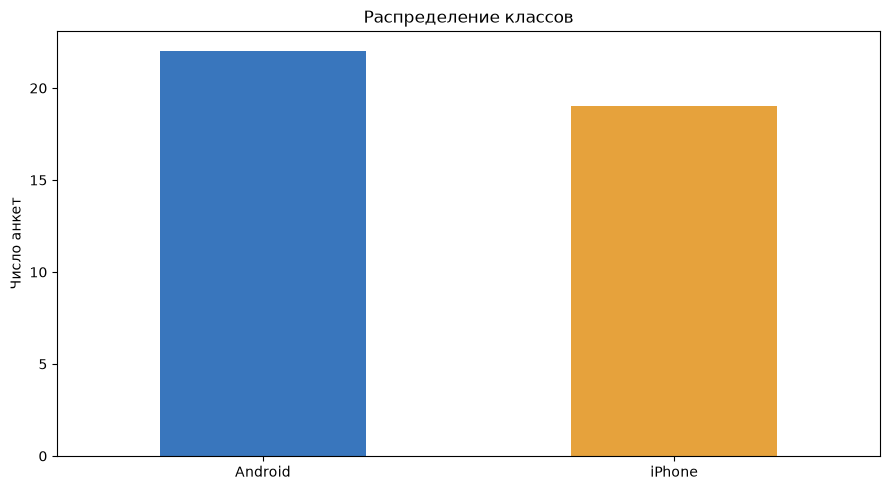

In [2]:
data = raw.copy()
for col in data.columns:
    data[col] = data[col].str.casefold().str.replace(r'\s+', ' ', regex=True)

def parse_budget(value):
    value = value.replace(' ', '').replace(',', '.')
    if re.fullmatch(r'\d{1,3}(\.\d{3})+', value):
        value = value.replace('.', '')
    value = float(value)
    return np.nan if value < 10 else value * 1000 if value < 1000 else value

numeric = ['q7', 'q8', 'q9', 'q13', 'q18', 'q21']
for col in numeric:
    data[col] = data[col].map(parse_budget) if col == 'q8' else pd.to_numeric(data[col], errors='coerce')
data.loc[~data.q7.between(14, 100), 'q7'] = np.nan
it_aliases = {'it', 'ит', 'программист', 'программирование', 'разработка', 'тех под', 'корпоративные системы'}
data['q15'] = data.q15.map(lambda x: 'it' if x in it_aliases else x)
assert set(data.q22) <= {'айфон', 'андроид'}
y = data.q22.map({'андроид': 0, 'айфон': 1}).to_numpy()
X = data.drop(columns=['timestamp', 'q22'])
categorical = [c for c in X if c not in numeric + ['q4']]
print('Изменённые бюджеты и сомнительные значения:')
mask = raw.q8.str.contains(r'\.', regex=True) | (pd.to_numeric(raw.q8, errors='coerce') < 1000) | data.q7.isna()
display(pd.DataFrame({'исходный бюджет': raw.q8, 'бюджет, руб.': data.q8, 'исходный возраст': raw.q7, 'возраст': data.q7}).loc[mask])
counts = pd.Series(y).map(CLASS_NAMES).value_counts()
display(counts.rename('число анкет').to_frame())
counts.plot.bar(color=['#3976bd', '#e6a23c'], rot=0, title='Распределение классов')
plt.ylabel('Число анкет'); plt.tight_layout(); plt.show()

In [3]:
def fit_preprocessor(frame):
    medians = frame[numeric].median().fillna(0)
    values = frame[numeric].fillna(medians)
    means = values.mean()
    stds = values.std(ddof=0).replace(0, 1)
    categories = {col: sorted(frame[col].unique()) for col in categorical}
    options = sorted({v.strip() for text in frame.q4 for v in text.split(';') if v.strip() and v.strip() != 'мультивыбор'})
    return medians, means, stds, categories, options

def transform(frame, state):
    medians, means, stds, categories, options = state
    blocks = [((frame[numeric].fillna(medians) - means) / stds).to_numpy(float)]
    names = numeric.copy()
    for col, cats in categories.items():
        blocks.append(np.column_stack([(frame[col] == cat).to_numpy(float) for cat in cats]) / np.sqrt(2))
        names.extend([f'{col}={cat}' for cat in cats])
    selections = frame.q4.map(lambda s: set(s.split(';')))
    blocks.append(np.column_stack([selections.map(lambda s: opt in s).to_numpy(float) for opt in options]))
    names.extend([f'q4={opt}' for opt in options])
    result = np.column_stack(blocks)
    assert np.isfinite(result).all()
    return result, names

def stratified_holdout(labels, fraction=0.2, seed=SEED):
    rng = np.random.default_rng(seed)
    train, test = [], []
    for cls in np.unique(labels):
        indices = rng.permutation(np.flatnonzero(labels == cls))
        n = max(1, round(len(indices) * fraction))
        test.extend(indices[:n]); train.extend(indices[n:])
    return rng.permutation(train), rng.permutation(test)

train_idx, test_idx = stratified_holdout(y)
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
assert not set(train_idx) & set(test_idx)
print('Обучение:', len(train_idx), '; тест:', len(test_idx))
display(pd.DataFrame({'обучение': pd.Series(y_train).map(CLASS_NAMES).value_counts(), 'тест': pd.Series(y_test).map(CLASS_NAMES).value_counts()}))

Обучение: 33 ; тест: 8


,обучение,тест
Android,18,4
iPhone,15,4


## Собственная реализация взвешенного k-NN

Евклидово расстояние: $d(x,z)=\sqrt{\sum_j(x_j-z_j)^2}$. Для k соседей суммируем голоса с весами $w_i=1/(d_i+10^{-10})$. Если есть точные совпадения, голосуют только они. При равных весах выбирается Android (код 0), что делает правило воспроизводимым. k не может превышать число обучающих объектов.

In [4]:
def calculate_distances(train, query):
    return np.sqrt(np.sum((query[:, None, :] - train[None, :, :]) ** 2, axis=2))

def weighted_knn_predict(train, labels, query, k, return_neighbors=False):
    if not 1 <= k <= len(train):
        raise ValueError('k должен находиться между 1 и размером обучения')
    distances = calculate_distances(train, query)
    indices = np.argsort(distances, axis=1, kind='stable')[:, :k]
    nearest = np.take_along_axis(distances, indices, axis=1)
    neighbor_labels = labels[indices]
    exact = nearest <= 1e-10
    weights = np.where(exact.any(axis=1, keepdims=True), exact.astype(float), 1 / (nearest + 1e-10))
    scores = np.column_stack([(weights * (neighbor_labels == c)).sum(axis=1) for c in (0, 1)])
    prediction = scores.argmax(axis=1)
    return (prediction, indices, nearest, weights) if return_neighbors else prediction

def accuracy_score_manual(truth, prediction):
    return float(np.mean(truth == prediction))

# Проверяем существенные случаи: совпадение, ближайший сосед и недопустимый k.
assert weighted_knn_predict(np.array([[0.], [2.]]), np.array([1, 0]), np.array([[0.]]), 2)[0] == 1
assert weighted_knn_predict(np.array([[0.], [2.]]), np.array([1, 0]), np.array([[1.9]]), 1)[0] == 0
try:
    weighted_knn_predict(np.array([[0.]]), np.array([0]), np.array([[1.]]), 2)
except ValueError:
    pass
else:
    raise AssertionError('Нет проверки k')

## Подбор k на обучающей выборке

Используем стратифицированную перекрёстную проверку по 4 блокам. Каждый объект обучения один раз выступает проверочным. Для каждого k объединяем правильные ответы всех блоков. При равном качестве выбираем меньшее k. Тест не участвует в выборе. Диапазон ограничен размером самой маленькой обучающей части блока.

,k,CV accuracy
0,1,0.696970
1,2,0.696970
2,3,0.787879
3,4,0.757576
4,5,0.787879
5,6,0.757576
6,7,0.727273
7,8,0.727273
8,9,0.727273
9,10,0.727273


Выбранное k: 3


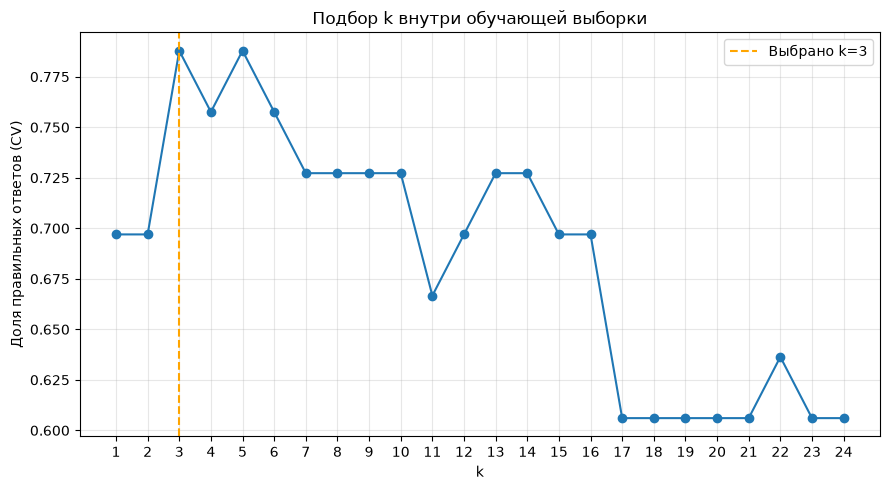

In [5]:
rng = np.random.default_rng(SEED)
folds = [[] for _ in range(4)]
for cls in (0, 1):
    parts = np.array_split(rng.permutation(np.flatnonzero(y_train == cls)), 4)
    for fold, part in zip(folds, parts):
        fold.extend(part)
folds = [np.array(f, dtype=int) for f in folds]
max_k = min(30, min(len(y_train) - len(f) for f in folds))
k_values = np.arange(1, max_k + 1)
correct = np.zeros(max_k)
fold_scores = []
for valid in folds:
    fit = np.setdiff1d(np.arange(len(y_train)), valid)
    state = fit_preprocessor(X_train.iloc[fit])
    a, _ = transform(X_train.iloc[fit], state)
    b, _ = transform(X_train.iloc[valid], state)
    scores = []
    for pos, k in enumerate(k_values):
        pred = weighted_knn_predict(a, y_train[fit], b, int(k))
        correct[pos] += (pred == y_train[valid]).sum()
        scores.append(accuracy_score_manual(y_train[valid], pred))
    fold_scores.append(scores)
cv_accuracy = correct / len(y_train)
best_k = int(k_values[np.argmax(cv_accuracy)])
results = pd.DataFrame({'k': k_values, 'CV accuracy': cv_accuracy})
display(results)
print('Выбранное k:', best_k)
plt.plot(k_values, cv_accuracy, 'o-')
plt.axvline(best_k, color='orange', linestyle='--', label=f'Выбрано k={best_k}')
plt.xlabel('k'); plt.ylabel('Доля правильных ответов (CV)')
plt.title('Подбор k внутри обучающей выборки'); plt.xticks(k_values); plt.grid(alpha=.3); plt.legend(); plt.tight_layout(); plt.show()

## Независимое тестирование

После выбора k готовим признаки на всём обучении. Сравниваем с простым правилом: всегда предсказывать самый частый класс обучения. Матрица ошибок: строки — истинный класс, столбцы — предсказанный.

In [6]:
state = fit_preprocessor(X_train)
A, feature_names = transform(X_train, state)
B, _ = transform(X_test, state)
pred, neighbors, distances, weights = weighted_knn_predict(A, y_train, B, best_k, True)
test_accuracy = accuracy_score_manual(y_test, pred)
majority = int(np.bincount(y_train, minlength=2).argmax())
baseline_accuracy = accuracy_score_manual(y_test, np.full(len(y_test), majority))
cm = np.zeros((2, 2), dtype=int)
np.add.at(cm, (y_test, pred), 1)
print(f'Признаков после кодирования: {A.shape[1]}')
print(f'k = {best_k}; CV accuracy = {cv_accuracy.max():.2%}')
print(f'Тест: {(pred == y_test).sum()} из {len(y_test)}, accuracy = {test_accuracy:.2%}')
print(f'Базовое правило ({CLASS_NAMES[majority]}): {baseline_accuracy:.2%}')
display(pd.DataFrame(cm, index=['Факт Android', 'Факт iPhone'], columns=['Прогноз Android', 'Прогноз iPhone']))
rows = []
for cls in (0, 1):
    tp = cm[cls, cls]
    precision = tp / cm[:, cls].sum() if cm[:, cls].sum() else 0
    recall = tp / cm[cls].sum() if cm[cls].sum() else 0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0
    rows.append([CLASS_NAMES[cls], precision, recall, f1, cm[cls].sum()])
display(pd.DataFrame(rows, columns=['Класс', 'Precision', 'Recall', 'F1', 'Объектов']))
display(pd.DataFrame({'строка CSV (с заголовком)': test_idx + 2, 'истинный класс': [CLASS_NAMES[v] for v in y_test], 'прогноз': [CLASS_NAMES[v] for v in pred], 'верно': pred == y_test}))

Признаков после кодирования: 51
k = 3; CV accuracy = 78.79%
Тест: 7 из 8, accuracy = 87.50%
Базовое правило (Android): 50.00%


,Прогноз Android,Прогноз iPhone
Факт Android,3,1
Факт iPhone,0,4


,Класс,Precision,Recall,F1,Объектов
0,Android,1.0,0.75,0.857143,4
1,iPhone,0.8,1.00,0.888889,4


,строка CSV (с заголовком),истинный класс,прогноз,верно
0,22,Android,Android,True
1,42,Android,iPhone,False
2,34,Android,Android,True
3,30,Android,Android,True
4,41,iPhone,iPhone,True
5,18,iPhone,iPhone,True
6,16,iPhone,iPhone,True
7,15,iPhone,iPhone,True


## Разбор первого тестового объекта и визуализация соседей

Выбираем первый тестовый объект без поиска удобного примера. Таблица показывает соседей для выбранного k. График — проекция на бюджет и кастомизацию; расстояния вычислены по **всем** кодированным признакам, поэтому близость на картинке может отличаться от близости для модели.

,строка CSV,класс,расстояние,вес
0,5,iPhone,2.279349,0.438722
1,26,Android,2.425482,0.412289
2,19,Android,2.868052,0.348669


Прогноз: Android ; факт: Android


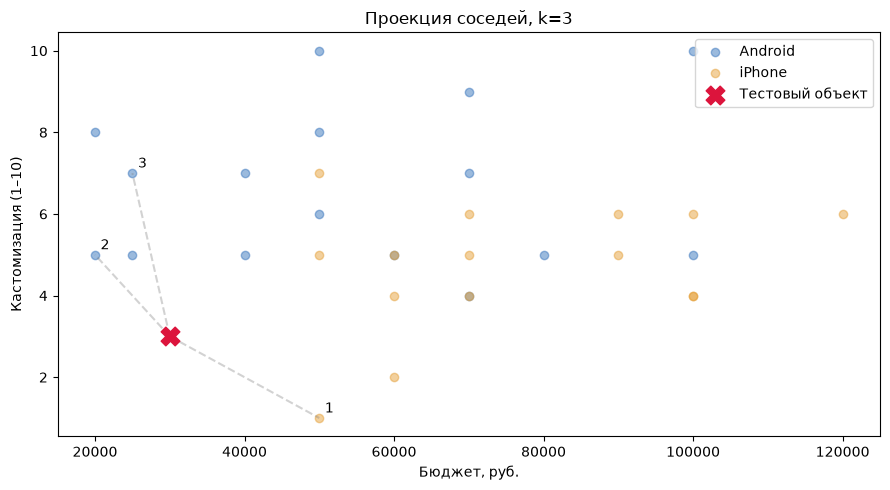

In [7]:
test_point = 0
idx = neighbors[test_point]
display(pd.DataFrame({'строка CSV': train_idx[idx] + 2, 'класс': [CLASS_NAMES[c] for c in y_train[idx]], 'расстояние': distances[test_point], 'вес': weights[test_point]}))
print('Прогноз:', CLASS_NAMES[pred[test_point]], '; факт:', CLASS_NAMES[y_test[test_point]])
fig, ax = plt.subplots()
colors = ['#3976bd', '#e6a23c']
for cls in (0, 1):
    mask = y_train == cls
    ax.scatter(X_train.q8.to_numpy()[mask], X_train.q9.to_numpy()[mask], c=colors[cls], label=CLASS_NAMES[cls], alpha=.5)
# Для сомнительного бюджета показываем ту же медиану, что использует модель.
train_budget = X_train.q8.fillna(state[0]['q8']).to_numpy()
test_budget = X_test.q8.fillna(state[0]['q8']).iloc[test_point]
test_custom = X_test.q9.iloc[test_point]
for rank, j in enumerate(idx, 1):
    ax.plot([test_budget, train_budget[j]], [test_custom, X_train.q9.iloc[j]], '--', color='gray', alpha=.35)
    ax.annotate(str(rank), (train_budget[j], X_train.q9.iloc[j]), xytext=(4, 4), textcoords='offset points')
ax.scatter([test_budget], [test_custom], marker='X', s=180, c='crimson', label='Тестовый объект', zorder=5)
ax.set(xlabel='Бюджет, руб.', ylabel='Кастомизация (1–10)', title=f'Проекция соседей, k={best_k}')
ax.legend(); fig.tight_layout(); plt.show()

## Вывод

Следующая ячейка формирует вывод из фактически вычисленных результатов. На 41 анкете нельзя обосновать универсальную модель для всех пользователей: выборка небольшая и преимущественно состоит из людей близкого возраста. Один ответ заметно меняет тестовую accuracy. Допущения о бюджете нужно подтвердить у авторов анкеты. Признаки отражают ассоциации, а не причины выбора телефона.

In [8]:
print(f'Для этой выборки по 4-блочной проверке выбрано k={best_k} (CV {cv_accuracy.max():.2%}).')
print(f'Независимый тест: accuracy {test_accuracy:.2%}; базовое правило {baseline_accuracy:.2%}.')
print(f'Один ответ на тесте меняет accuracy на {100 / len(y_test):.1f} процентного пункта.')
print('Малое k чувствительно к отдельным анкетам; большое k сглаживает различия и может предпочитать частый класс.')
print('Результат относится к данному разделению и правилам подготовки; для устойчивого вывода нужно больше анкет.')

Для этой выборки по 4-блочной проверке выбрано k=3 (CV 78.79%).
Независимый тест: accuracy 87.50%; базовое правило 50.00%.
Один ответ на тесте меняет accuracy на 12.5 процентного пункта.
Малое k чувствительно к отдельным анкетам; большое k сглаживает различия и может предпочитать частый класс.
Результат относится к данному разделению и правилам подготовки; для устойчивого вывода нужно больше анкет.
